In [76]:
import numpy as np
from scipy.integrate import solve_ivp

water_density = 1000.0
air_molar_mass = 28.9647e-3
water_molar_mass = 18.02e-3
R = 8.314
pressure = 101325.0
binary_diffusion = 0.242e-4
specific_vapourisation_heat = 2453.6e3
air_thermal_conductivity = 25.87e-3
water_specific_heat_capacity = 4180.0

def water_vapour_pressure(temperature:float)->float:
    return 610.78*np.exp(17.27*(temperature-273.15)/(temperature-273.15+237.3))

def create_model(environment_temperature:float, rh:float):
    air_density = air_molar_mass * pressure/(R*environment_temperature) #PV = nRT, P/RT = n/V = density/M
    humidity = water_vapour_pressure(environment_temperature)*rh
    def dxdt(time:float, state):
        mass = state[0]
        volume = mass/water_density
        radius = np.cbrt(3*volume/(4*np.pi))
        droplet_temperature = state[1]
        droplet_vapour_pressure = water_vapour_pressure(droplet_temperature)
        dmdt = 4*np.pi*radius*air_density*(water_molar_mass / air_molar_mass) * binary_diffusion * np.log((pressure-droplet_vapour_pressure)/(pressure-humidity))
        latent_heat = dmdt*specific_vapourisation_heat
        conduction = 4*np.pi*radius*air_thermal_conductivity * (environment_temperature-droplet_temperature)
        return np.array([dmdt, (latent_heat+conduction)/(mass*water_specific_heat_capacity)])
    return dxdt

In [77]:
initial_radius = 25e-6
initial_temperature = 293.15
model = create_model(initial_temperature,0.5)

In [78]:
initial_mass = 4/3*np.pi*initial_radius**3 * water_density
initial_state = np.array([initial_mass, initial_temperature])
solution = solve_ivp(model,(0,4),initial_state,method="LSODA",rtol=1e-9,atol=1e-9)

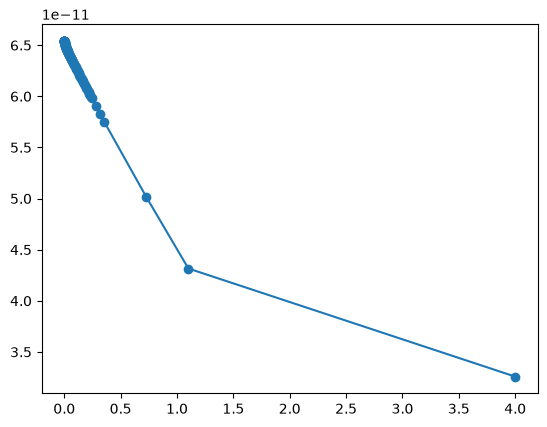

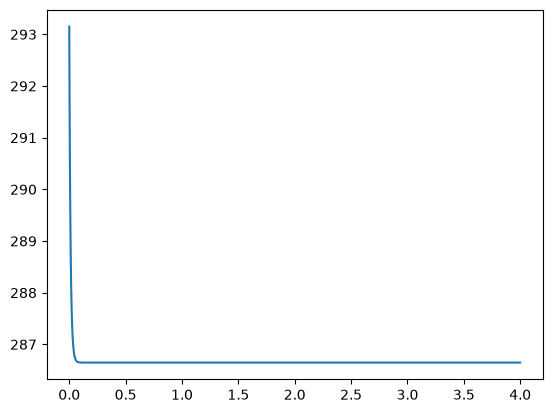

In [79]:
import matplotlib.pyplot as plt

masses = solution.y[0]
temperatures = solution.y[1]

plt.plot(solution.t, masses)
plt.scatter(solution.t, masses)
plt.show()

plt.plot(solution.t, temperatures)
plt.show()

In [80]:
def create_log_model(environment_temperature:float, rh:float):
    air_density = air_molar_mass * pressure/(R*environment_temperature) #PV = nRT, P/RT = n/V = density/M
    humidity = water_vapour_pressure(environment_temperature)*rh
    def dlogxdt(time:float, state):
        mass = np.exp(state[0])
        volume = mass/water_density
        radius = np.cbrt(3*volume/(4*np.pi))
        droplet_temperature = np.exp(state[1])
        droplet_vapour_pressure = water_vapour_pressure(droplet_temperature)
        dmdt = 4*np.pi*radius*air_density*(water_molar_mass / air_molar_mass) * binary_diffusion * np.log((pressure-droplet_vapour_pressure)/(pressure-humidity))
        latent_heat = dmdt*specific_vapourisation_heat
        conduction = 4*np.pi*radius*air_thermal_conductivity * (environment_temperature-droplet_temperature)
        return np.array([dmdt/mass, (latent_heat+conduction)/(droplet_temperature*mass*water_specific_heat_capacity)])
    return dlogxdt

In [81]:
model = create_log_model(initial_temperature,0.5)
initial_state = np.log(np.array([initial_mass, initial_temperature]))
solution = solve_ivp(model,(0,4),initial_state,method="LSODA",first_step=1e-9,rtol=1e-6,atol=1e-6)

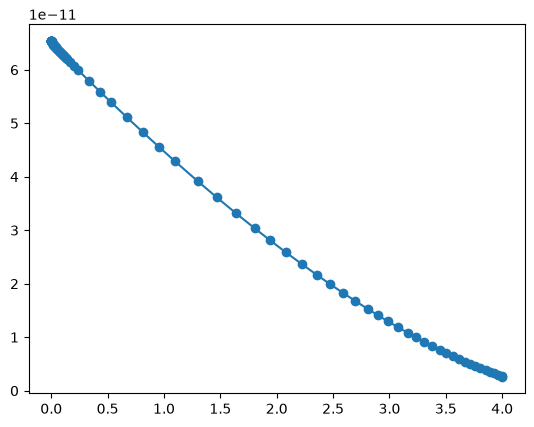

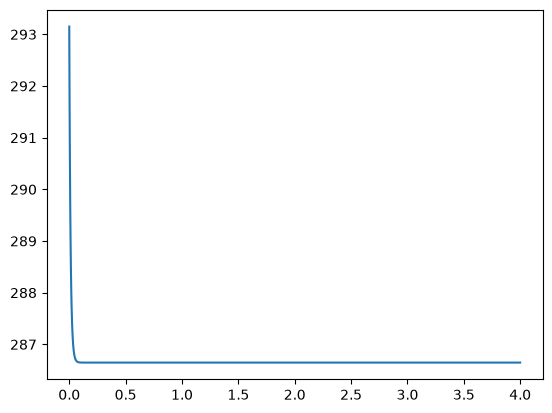

In [82]:
masses = np.exp(solution.y[0])
temperatures = np.exp(solution.y[1])

plt.plot(solution.t, masses)
plt.scatter(solution.t, masses)
plt.show()

plt.plot(solution.t, temperatures)
plt.show()